In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
filepath ="/content/drive/MyDrive/AI_ ML_Class_Works/dataset/Student_Depression_Dataset.csv"
df_student_data=pd.read_csv(filepath)

In [3]:
df_student_data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
df_student_data.shape

(4464, 13)

In [5]:
df_student_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [6]:
df_student_data.dtypes

,0
Gender,object
Age,int64
Family_background,object
Relationship_status,object
Marital_status,object
Living_style,object
Current_semester,int64
CGPA,float64
friend_circle,object
Health_condition,object


In [7]:
#Handling missing values
df_student_data.isna().sum()


,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [8]:
#handling duplicates
print(df_student_data.duplicated().sum())

0


#numerical data -- missing values,duplicates,standard scaling,outliers
#categorical data -- missing values,duplicates,encoding

In [9]:
num_cols = df_student_data.select_dtypes(include=["number"]).columns
cat_cols = df_student_data.select_dtypes(include=["object"]).columns

In [10]:
print(num_cols)

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')


In [11]:
print(cat_cols)

Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')


#handling mising values -- no missing values.





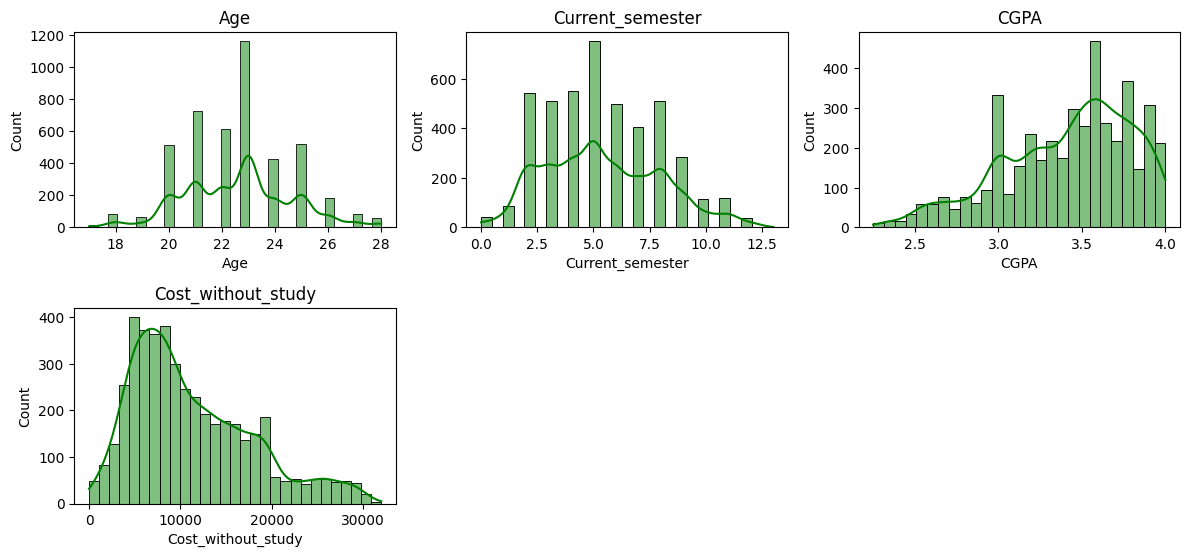

In [12]:
#histogram for numerical values
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
  plt.subplot(3,3,i)
  sns.histplot(df_student_data[col],kde=True,color="green")
  plt.title(col)
plt.tight_layout()
plt.show()  # no missing value

##Handling duplictaes -- no duplicates

##Standard Scaler

In [13]:
X=df_student_data.drop(columns=["Depression"],axis=1)
y=df_student_data["Depression"]
print(X.columns.tolist())
print(y.name)

['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division']
Depression


In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [15]:
print(X_train.shape)
print(X_train.head())

(3571, 12)
      Gender  Age   Family_background Relationship_status Marital_status  \
3918    Male   20        Middle class              Single        Married   
2807  Female   23        Middle class              Single      Unmarried   
1406    Male   22  Lower Middle class              Single      Unmarried   
3154  Female   24  Lower Middle class              Single      Unmarried   
2598  Female   22        Middle class   In a Relationship        Married   

     Living_style  Current_semester  CGPA friend_circle Health_condition  \
3918     Bachelor                 8  3.00           Yes         Abnormal   
2807       Family                 4  3.39           Yes           Normal   
1406       Family                 5  3.58           Yes             Good   
3154       Family                 3  3.84           Yes             Good   
2598       Family                 3  4.00           Yes             Good   

      Cost_without_study Home_division  
3918               15091         D

In [16]:
X_test.shape

(893, 12)

In [17]:
X_train_num_cols=X_train.select_dtypes(include=["number"])
X_test_num_cols=X_test.select_dtypes(include=["number"])
print(X_train_num_cols.head())
print(X_test_num_cols.head())

      Age  Current_semester  CGPA  Cost_without_study
3918   20                 8  3.00               15091
2807   23                 4  3.39                5900
1406   22                 5  3.58                5000
3154   24                 3  3.84                9000
2598   22                 3  4.00                4800
      Age  Current_semester  CGPA  Cost_without_study
297    24                 3  3.70               17135
969    20                 5  3.86               12260
2037   22                 5  3.40                9400
598    20                 4  3.93               16311
3411   21                 4  3.32               12500


In [18]:
scaler=StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_num_cols)
X_test_scaled = scaler.transform(X_test_num_cols)

X_train[X_train_num_cols.columns] = X_train_scaled
X_test[X_test_num_cols.columns] = X_test_scaled


print(X_train.head())
print(X_test.head())

      Gender       Age   Family_background Relationship_status Marital_status  \
3918    Male -1.296573        Middle class              Single        Married   
2807  Female  0.196674        Middle class              Single      Unmarried   
1406    Male -0.301075  Lower Middle class              Single      Unmarried   
3154  Female  0.694424  Lower Middle class              Single      Unmarried   
2598  Female -0.301075        Middle class   In a Relationship        Married   

     Living_style  Current_semester      CGPA friend_circle Health_condition  \
3918     Bachelor          1.008166 -1.074410           Yes         Abnormal   
2807       Family         -0.548156 -0.065802           Yes           Normal   
1406       Family         -0.159075  0.425571           Yes             Good   
3154       Family         -0.937236  1.097976           Yes             Good   
2598       Family         -0.937236  1.511764           Yes             Good   

      Cost_without_study Home_di

##outliers handling

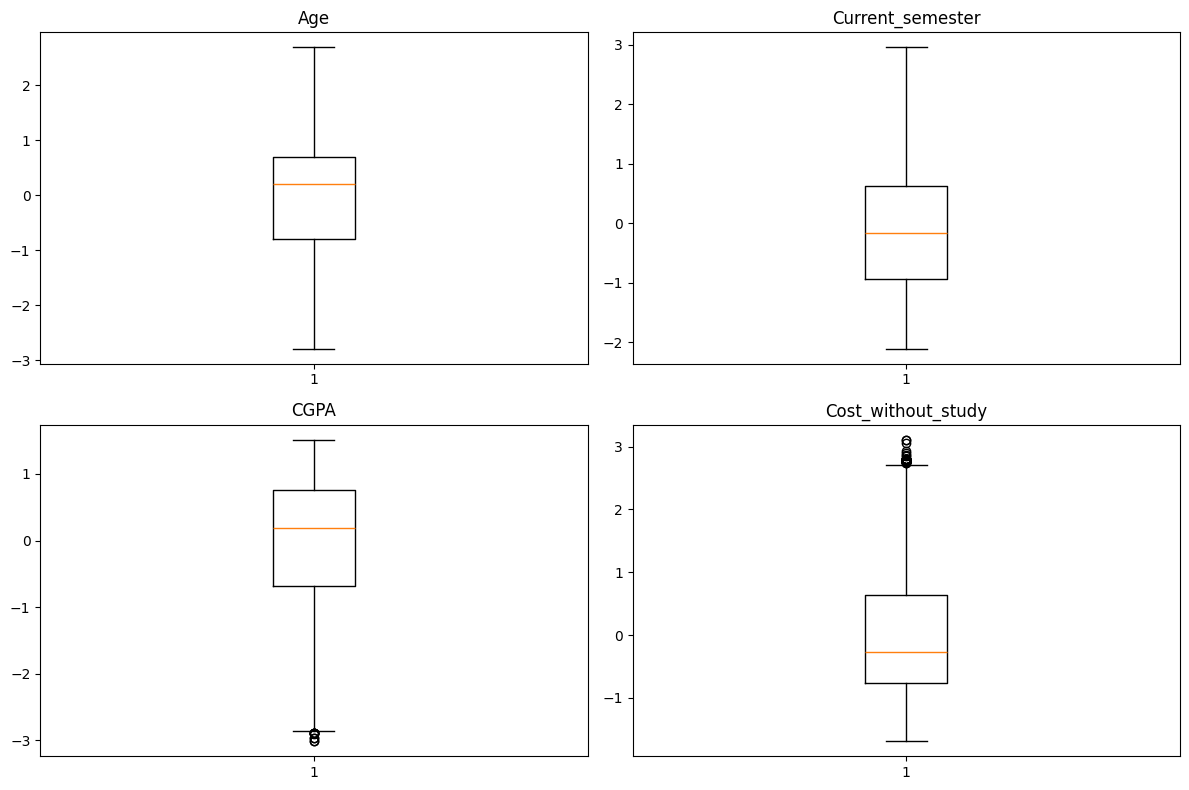

In [19]:
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(X_train[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [20]:
Q1=X_train[num_cols].quantile(0.25)
Q2=X_train[num_cols].quantile(0.50)
Q3=X_train[num_cols].quantile(0.75)
IQR=Q3-Q1
lower_b=Q1-(1.5*IQR)
upper_b=Q3+(1.5*IQR)
outliers=((X_train[num_cols]>upper_b) | (X_train[num_cols])).sum()
print(outliers)
X_train[num_cols]=X_train[num_cols].clip(lower=lower_b,upper=upper_b,axis=1)
X_test[num_cols]=X_test[num_cols].clip(lower=lower_b,upper=upper_b,axis=1)

Age                   3571
Current_semester      3571
CGPA                  3571
Cost_without_study    3571
dtype: int64


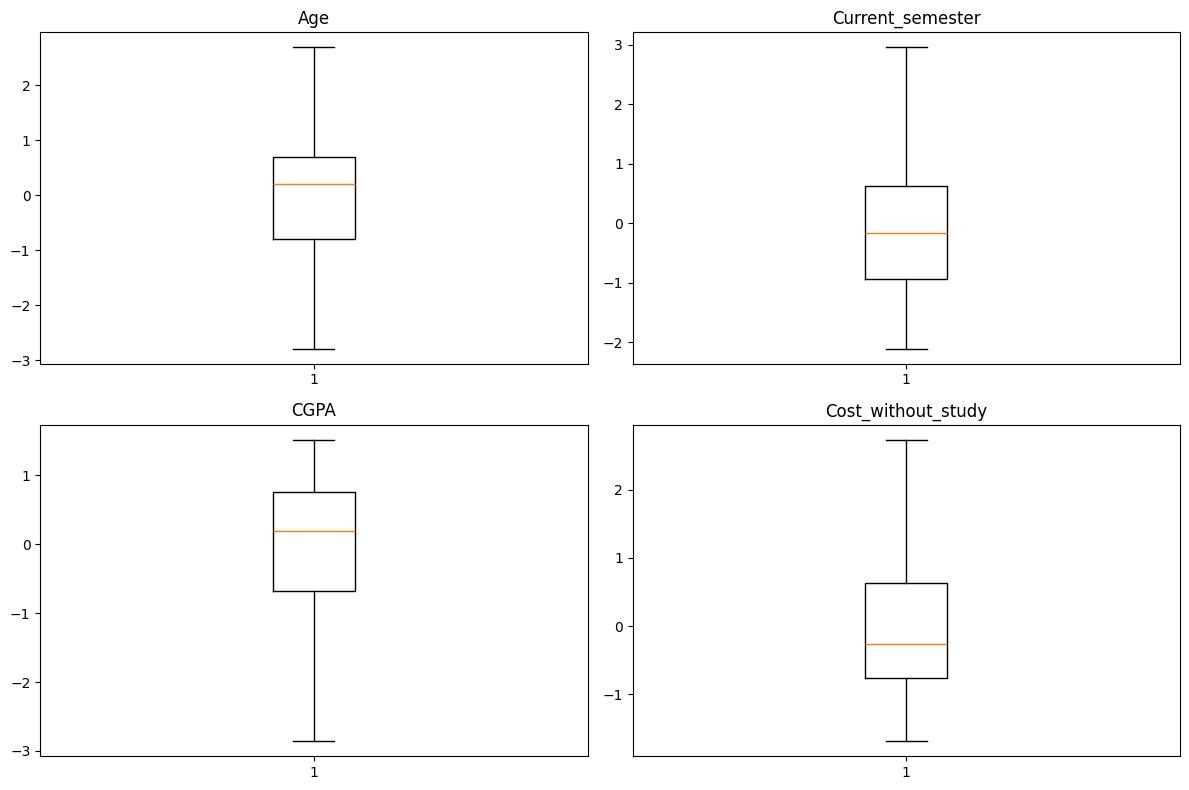

In [21]:
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(X_train[col])
  plt.title(col)
plt.tight_layout()
plt.show()

#categorical columns




In [22]:
X_train_cat_cols=df_student_data.select_dtypes(include=["object"])
X_test_cat_cols=df_student_data.select_dtypes(include=["object"])
print(X_train_cat_cols.columns.tolist())

['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division', 'Depression']


In [23]:
X_train_cat_cols.head()

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
0,Female,Middle class,Single,Unmarried,Bachelor,Yes,Critical,Chittagong,Yes
1,Male,Middle class,Single,Unmarried,Bachelor,Yes,Abnormal,Chittagong,Yes
2,Male,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes
3,Male,Middle class,Complicated,Unmarried,Family,No,Good,Dhaka,No
4,Female,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes


##Missing values for categorical columns

In [24]:
X_train_cat_cols.isna().sum()

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


In [25]:
y_train

,Depression
3918,No
2807,No
1406,No
3154,No
2598,No
...,...
4426,No
466,No
3092,Yes
3772,No


In [26]:
y_train.unique()


array(['No', 'Yes'], dtype=object)

In [27]:
##Student depression is the target column so depression so apply label encoding
label_encoder=LabelEncoder()
y_train=label_encoder.fit_transform(y_train)
y_test=label_encoder.transform(y_test)

In [28]:
np.unique(y_train)

array([0, 1])

In [29]:
np.unique(y_test)

array([0, 1])

In [30]:
X_train["Health_condition"].unique()


array(['Abnormal', 'Normal', 'Good', 'Critical'], dtype=object)

In [31]:
encoder_health = OrdinalEncoder(
    categories=[["Normal","Good","Abnormal","Critical"]]
)
X_train["Health_condition"]=encoder_health.fit_transform(X_train[["Health_condition"]])
X_test["Health_condition"]=encoder_health.transform(X_test[["Health_condition"]])


In [32]:
X_train["Health_condition"].unique()

array([2., 0., 1., 3.])

In [33]:
X_train["Family_background"].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [34]:
encoder_family = OrdinalEncoder(
    categories =[["Lower Middle class","Middle class","Rich class"]]
)
X_train["Family_background"]=encoder_family.fit_transform(X_train[["Family_background"]])
X_test["Family_background"]=encoder_family.fit_transform(X_test[["Family_background"]])

In [35]:
X_train["Family_background"].unique()

array([1., 0., 2.])

In [36]:
X_train["Relationship_status"].unique() # no ordinal

array(['Single', 'In a Relationship', 'Complicated'], dtype=object)

In [37]:
X_train["Living_style"].unique() # no ordinal

array(['Bachelor', 'Family'], dtype=object)

In [38]:
# so next columns has no order so all columns has encoded with one hot encoder
X_train["Gender"].unique()


array(['Male', 'Female'], dtype=object)

In [39]:
print(X_train.columns.tolist())

['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division']


In [40]:
features_to_encode = [
     'Gender',
    'Relationship_status',
    'Marital_status',
    'Living_style',
    'friend_circle',
    'Home_division'
]


X_train = pd.get_dummies(X_train, columns=features_to_encode, dtype=int)
X_test = pd.get_dummies(X_test, columns=features_to_encode, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print(X_train.head())

           Age  Family_background  Current_semester      CGPA  \
3918 -1.296573                1.0          1.008166 -1.074410   
2807  0.196674                1.0         -0.548156 -0.065802   
1406 -0.301075                0.0         -0.159075  0.425571   
3154  0.694424                0.0         -0.937236  1.097976   
2598 -0.301075                1.0         -0.937236  1.511764   

      Health_condition  Cost_without_study  Gender_Female  Gender_Male  \
3918               2.0            0.572576              0            1   
2807               0.0           -0.805371              1            0   
1406               1.0           -0.940302              0            1   
3154               1.0           -0.340608              1            0   
2598               1.0           -0.970287              1            0   

      Relationship_status_Complicated  Relationship_status_In a Relationship  \
3918                                0                                      0   
2807

In [41]:
X_train.head()

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,...,friend_circle_No,friend_circle_Yes,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
3918,-1.296573,1.0,1.008166,-1.074410,2.0,0.572576,0,1,0,0,...,0,1,0,0,1,0,0,0,0,0
2807,0.196674,1.0,-0.548156,-0.065802,0.0,-0.805371,1,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1406,-0.301075,0.0,-0.159075,0.425571,1.0,-0.940302,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
3154,0.694424,0.0,-0.937236,1.097976,1.0,-0.340608,1,0,0,0,...,0,1,0,0,0,0,1,0,0,0
2598,-0.301075,1.0,-0.937236,1.511764,1.0,-0.970287,1,0,0,1,...,0,1,0,0,0,0,0,0,0,1


In [42]:
X_train.columns

Index(['Age', 'Family_background', 'Current_semester', 'CGPA',
       'Health_condition', 'Cost_without_study', 'Gender_Female',
       'Gender_Male', 'Relationship_status_Complicated',
       'Relationship_status_In a Relationship', 'Relationship_status_Single',
       'Marital_status_Married', 'Marital_status_Separated',
       'Marital_status_Unmarried', 'Living_style_Bachelor',
       'Living_style_Family', 'friend_circle_No', 'friend_circle_Yes',
       'Home_division_Barisal', 'Home_division_Chittagong',
       'Home_division_Dhaka', 'Home_division_Khulna',
       'Home_division_Mymensingh', 'Home_division_Rajshahi',
       'Home_division_Rangpur', 'Home_division_Sylhet'],
      dtype='object')

In [43]:

print(X_train.shape, X_test.shape)
print(X_train.dtypes)
print((X_train.dtypes=="object").sum(), (X_test.dtypes=="object").sum())


(3571, 26) (893, 26)
Age                                      float64
Family_background                        float64
Current_semester                         float64
CGPA                                     float64
Health_condition                         float64
Cost_without_study                       float64
Gender_Female                              int64
Gender_Male                                int64
Relationship_status_Complicated            int64
Relationship_status_In a Relationship      int64
Relationship_status_Single                 int64
Marital_status_Married                     int64
Marital_status_Separated                   int64
Marital_status_Unmarried                   int64
Living_style_Bachelor                      int64
Living_style_Family                        int64
friend_circle_No                           int64
friend_circle_Yes                          int64
Home_division_Barisal                      int64
Home_division_Chittagong                   int64

In [44]:
train_full = pd.concat([X_train, pd.Series(y_train, index=X_train.index, name="Depression")], axis=1)
train_full.head(20)


,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,...,friend_circle_Yes,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Depression
3918,-1.296573,1.0,1.008166,-1.074410,2.0,0.572576,0,1,0,0,...,1,0,0,1,0,0,0,0,0,0
2807,0.196674,1.0,-0.548156,-0.065802,0.0,-0.805371,1,0,0,0,...,1,0,0,1,0,0,0,0,0,0
1406,-0.301075,0.0,-0.159075,0.425571,1.0,-0.940302,0,1,0,0,...,1,0,0,0,0,0,0,1,0,0
3154,0.694424,0.0,-0.937236,1.097976,1.0,-0.340608,1,0,0,0,...,1,0,0,0,0,1,0,0,0,0
2598,-0.301075,1.0,-0.937236,1.511764,1.0,-0.970287,1,0,0,1,...,1,0,0,0,0,0,0,0,1,0
1611,-0.798824,0.0,-0.937236,1.382455,1.0,-1.150195,0,1,0,0,...,1,0,0,1,0,0,0,0,0,0
3623,-0.798824,1.0,-0.548156,0.684188,1.0,0.109163,0,1,0,1,...,1,0,1,0,0,0,0,0,0,0
1345,-0.798824,1.0,-0.937236,-0.402005,0.0,0.260136,0,1,0,0,...,1,0,0,0,0,0,0,1,0,0
618,1.192173,2.0,0.230005,1.201423,1.0,1.762370,1,0,0,1,...,1,1,0,0,0,0,0,0,0,0
576,-0.301075,2.0,-1.326317,0.942805,3.0,1.688457,1,0,0,0,...,1,0,0,0,1,0,0,0,0,1
